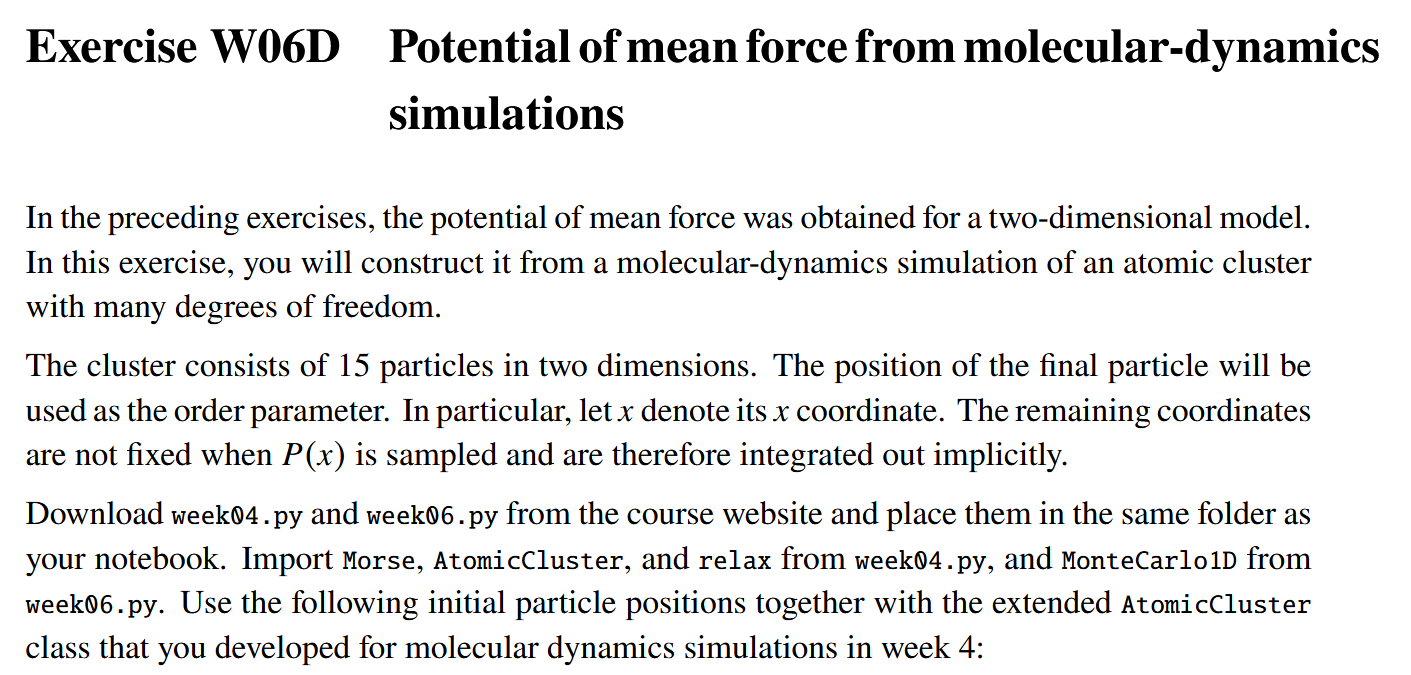

In [1]:
import numpy as np
import matplotlib.pyplot as plt 
from week04 import *
from week06 import *

a = np.sqrt (3) / 2
positions = np.array ([
    [-1 - 2*a, 0.0] ,
    [-1 - a, -0.5],
    [-1, -1.0],
    [-1 + a, -1.5],
    [ 1 + a, 0.5] ,
    [ 1 + a, -0.5],
    [ 1 + a, 1.5] ,
    [ 1 + a, -1.5],
    [ 1 + 2 * a, 1.0] ,
    [ 1 + 2 * a, 0.0] ,
    [ 1 + 2 * a, -1.0],
    [-1 - a, 0.5] ,
    [-1, 1.0] ,
    [-1 + a, 1.5] ,
    [ 0.5, 0.0] ,
])

static = [True]*14 + [False]

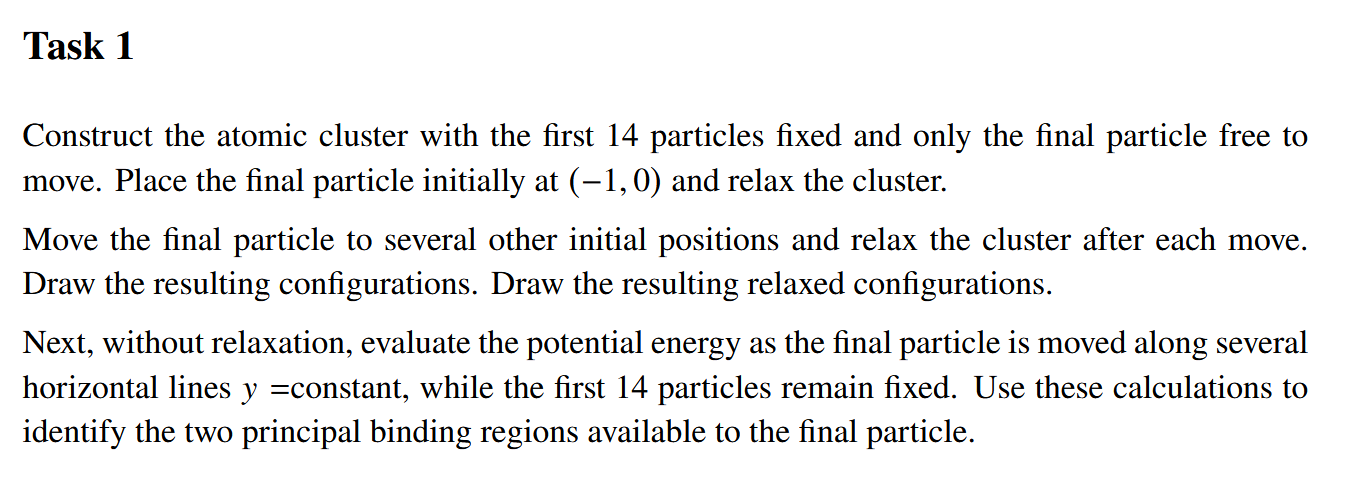

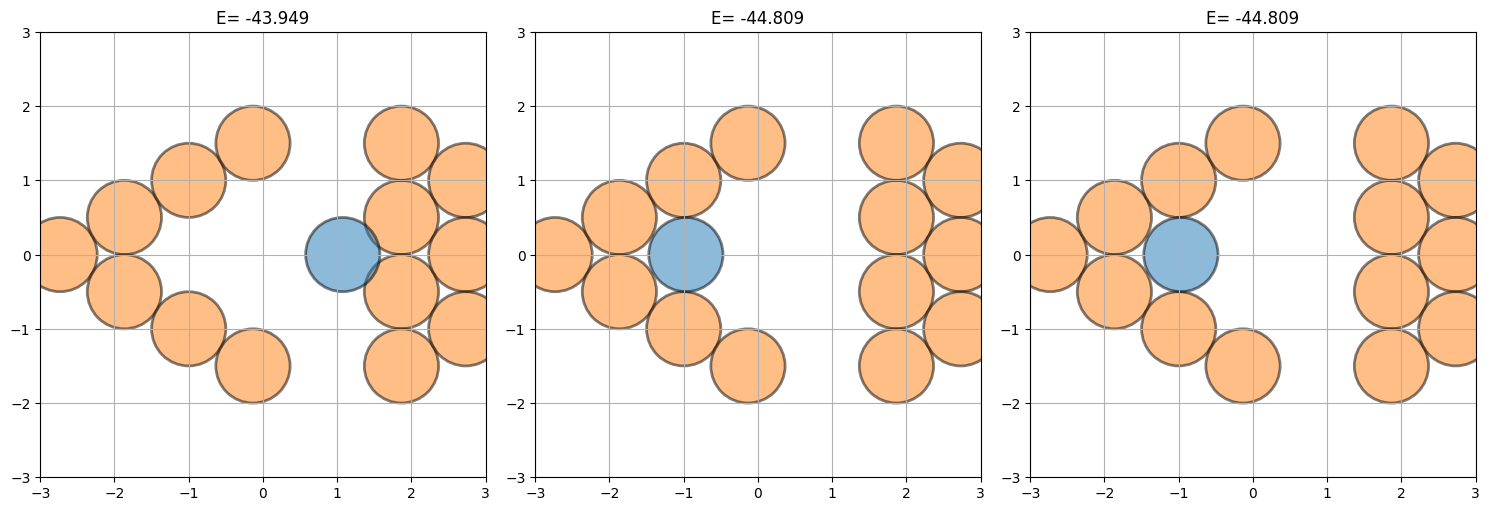

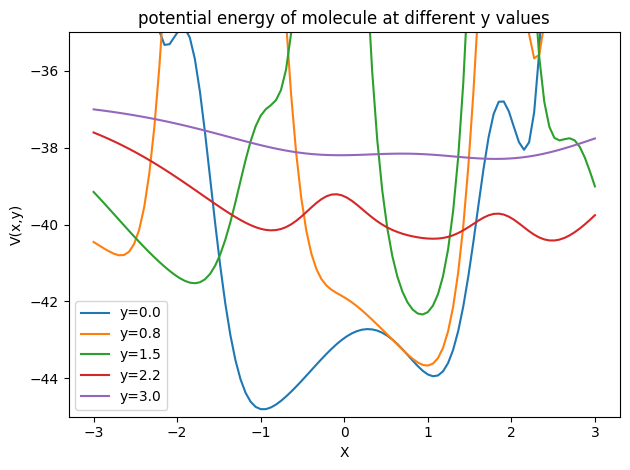

In [2]:
calc = Morse()
cluster = AtomicCluster(calc=calc, pos=positions, static=static)

pos = [[1,0], [0,0], [-1,0]]
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

def nice_plot(ax):
    ax.xaxis.set_major_locator(plt.MultipleLocator(1.0))
    ax.yaxis.set_major_locator(plt.MultipleLocator(1.0))
    ax.set_aspect('equal')
    ax.set_xlim([-3,3])
    ax.set_ylim([-3,3])
    ax.grid('on')

for i in range(len(pos)):
    cluster.pos[-1] = pos[i]
    relax(cluster)
    cluster.draw(ax[i])
    nice_plot(ax[i])

plt.tight_layout()
plt.show()

ys = np.linspace(0, 3, 5)
xs = np.linspace(-3, 3, 100)

for y in ys:
    V = []
    for x in xs:
        cluster.pos[-1] = [x, y]
        V.append(cluster.potential_energy)

    plt.plot(xs, V, label=f'y={y:.1f}')

plt.title(f'potential energy of molecule at different y values')
plt.xlabel(f'X')
plt.ylabel(f'V(x,y)')
plt.ylim(-45, -35)
plt.legend()
plt.tight_layout()
plt.show()

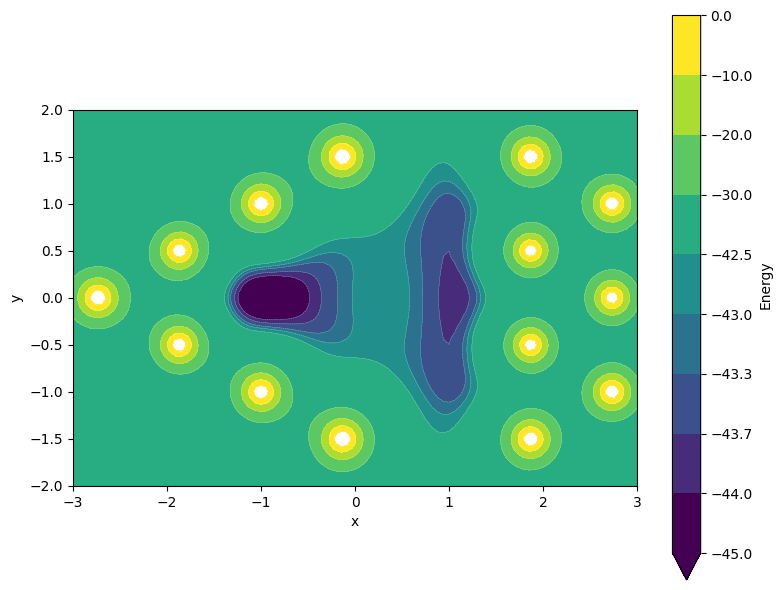

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

xs = np.linspace(-3, 3, 100)
ys = np.linspace(-2, 2, 100)
X, Y = np.meshgrid(xs, ys)
Z = np.zeros_like(X)

for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        cluster.pos[-1] = [X[i, j], Y[i, j]]
        Z[i, j] = cluster.potential_energy

fig, ax = plt.subplots(figsize=(8, 6))

levels = [-45, -44, -43.7, -43.3, -43, -42.5, -30, -20.0, -10.0, 0.0]

cmap = plt.get_cmap('viridis')
norm = mcolors.BoundaryNorm(levels, ncolors=cmap.N)

cf = ax.contourf(X, Y, Z, levels=levels, cmap=cmap, norm=norm, extend='min')

ax.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.3, alpha=0.5)

cbar = fig.colorbar(cf, ax=ax, spacing='uniform')
cbar.set_label('Energy')

ax.set_aspect('equal')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_xlim([-3, 3])
ax.set_ylim([-2, 2])

plt.tight_layout()
plt.show()

### Why $V(x,0)$ does not contain all the needed information:

* **Missing Entropy (Phase Space):** A 1D cut like $V(x,0)$ only reveals the absolute energy depth along a single mathematical line. It provides no information about the width or volume of the potential well extending into the $y$-direction.


* **The PMF Requirement:** True equilibrium probability is governed by the Boltzmann distribution integrated over all accessible microstates. To find the true distribution of $x$, you must calculate the marginal probability $P(x) \propto \int \exp(-V(x,y)/k_B T) dy$.
* **The Broad Well Effect:** As you proved in your earlier Helmholtz free energy exercises, a well that has a higher potential energy minimum (a shallower $V(x,0)$) can actually dominate the equilibrium population if it is substantially wider. The 2D contour plot reveals these widths, whereas a 1D slice entirely blindfolds you to the entropic advantage of wide wells.

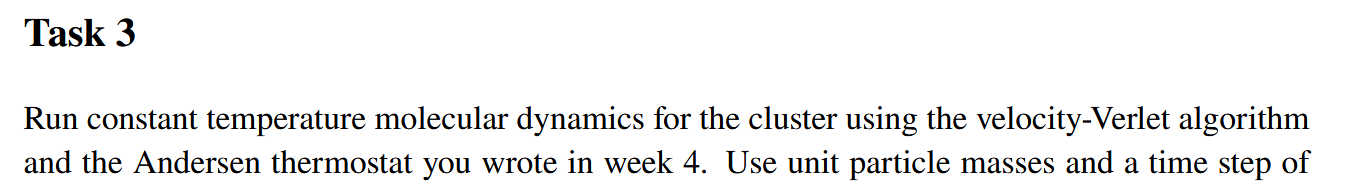
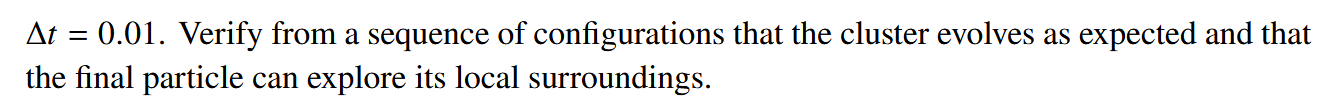
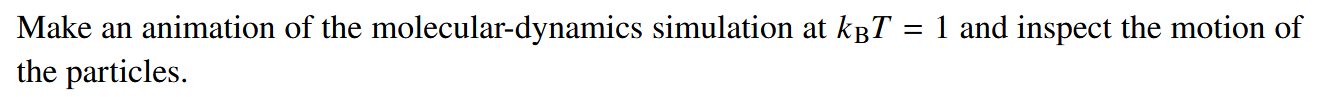

In [4]:
from Velocity_Verlet import *
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

class AtomicCluster(AtomicCluster):
    def __init__(self, *args, title=None, kT=0.15, **kwargs):
        super().__init__(*args, **kwargs)
        self.kT = kT
        self.title = title
        self.v = np.zeros(self.pos.shape)

    @property
    def K(self):
        return 0.5 * np.sum(self.v**2) # assume m=1

    def get_velocity(self):
        return self.v.copy()
    
    def set_velocity(self, v):
        self.v = v

    def draw_title(self, ax):
        ek = self.K
        ep = self.potential_energy
        etot = ek+ep
        ax.set_title(f'E={etot:7.2f}')


kT = 1.0
dt = 0.01

cluster = AtomicCluster(calc=calc, pos=positions, static=static, kT=kT)

cluster.pos[-1] = [-1.0, 0.0]
cluster.set_velocity(np.zeros_like(cluster.pos))

fig, ax = plt.subplots(figsize=(6, 6))

nice_plot(ax)
cluster.draw(ax)

def update(frame):
    # Apply the Andersen thermostat periodically 
    if frame % 10 == 0:
        thermostat(cluster, kT=1.0)
        
    # Evolve deterministically for a few steps
    velocity_verlet(cluster, N=10, dt=0.01)
    
    # Update the existing atom positions
    cluster.draw(ax)
    
    ax.set_title(f"MD Animation | $k_B T = 1.0$ | Frame {frame}")

# Create the animation
ani = FuncAnimation(fig, update, frames=100, interval=50)

# Prevent a static duplicate plot from appearing below the cell
plt.close(fig)

# Render inline video
HTML(ani.to_jshtml())

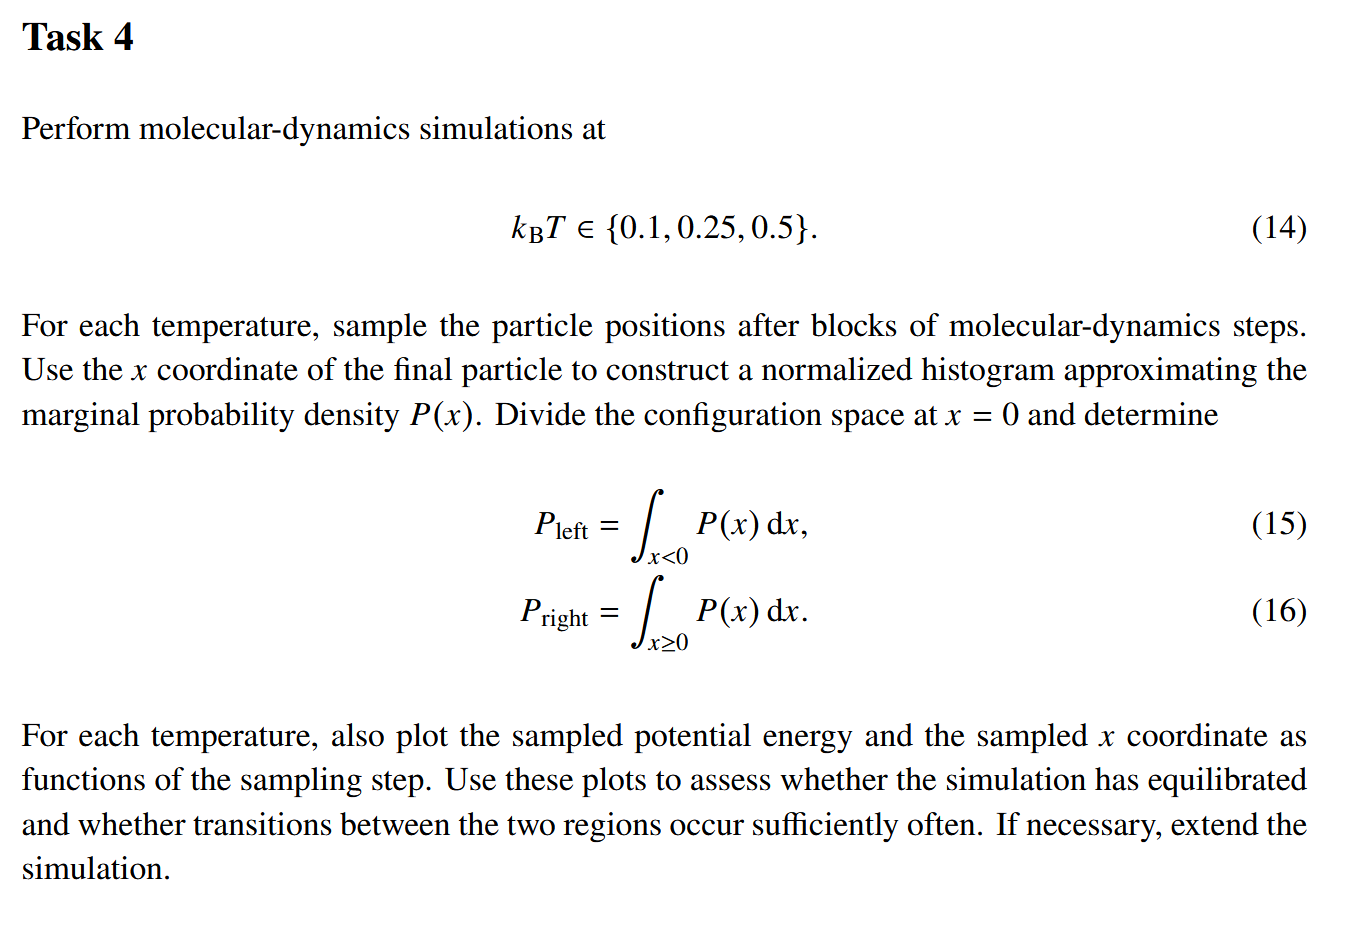

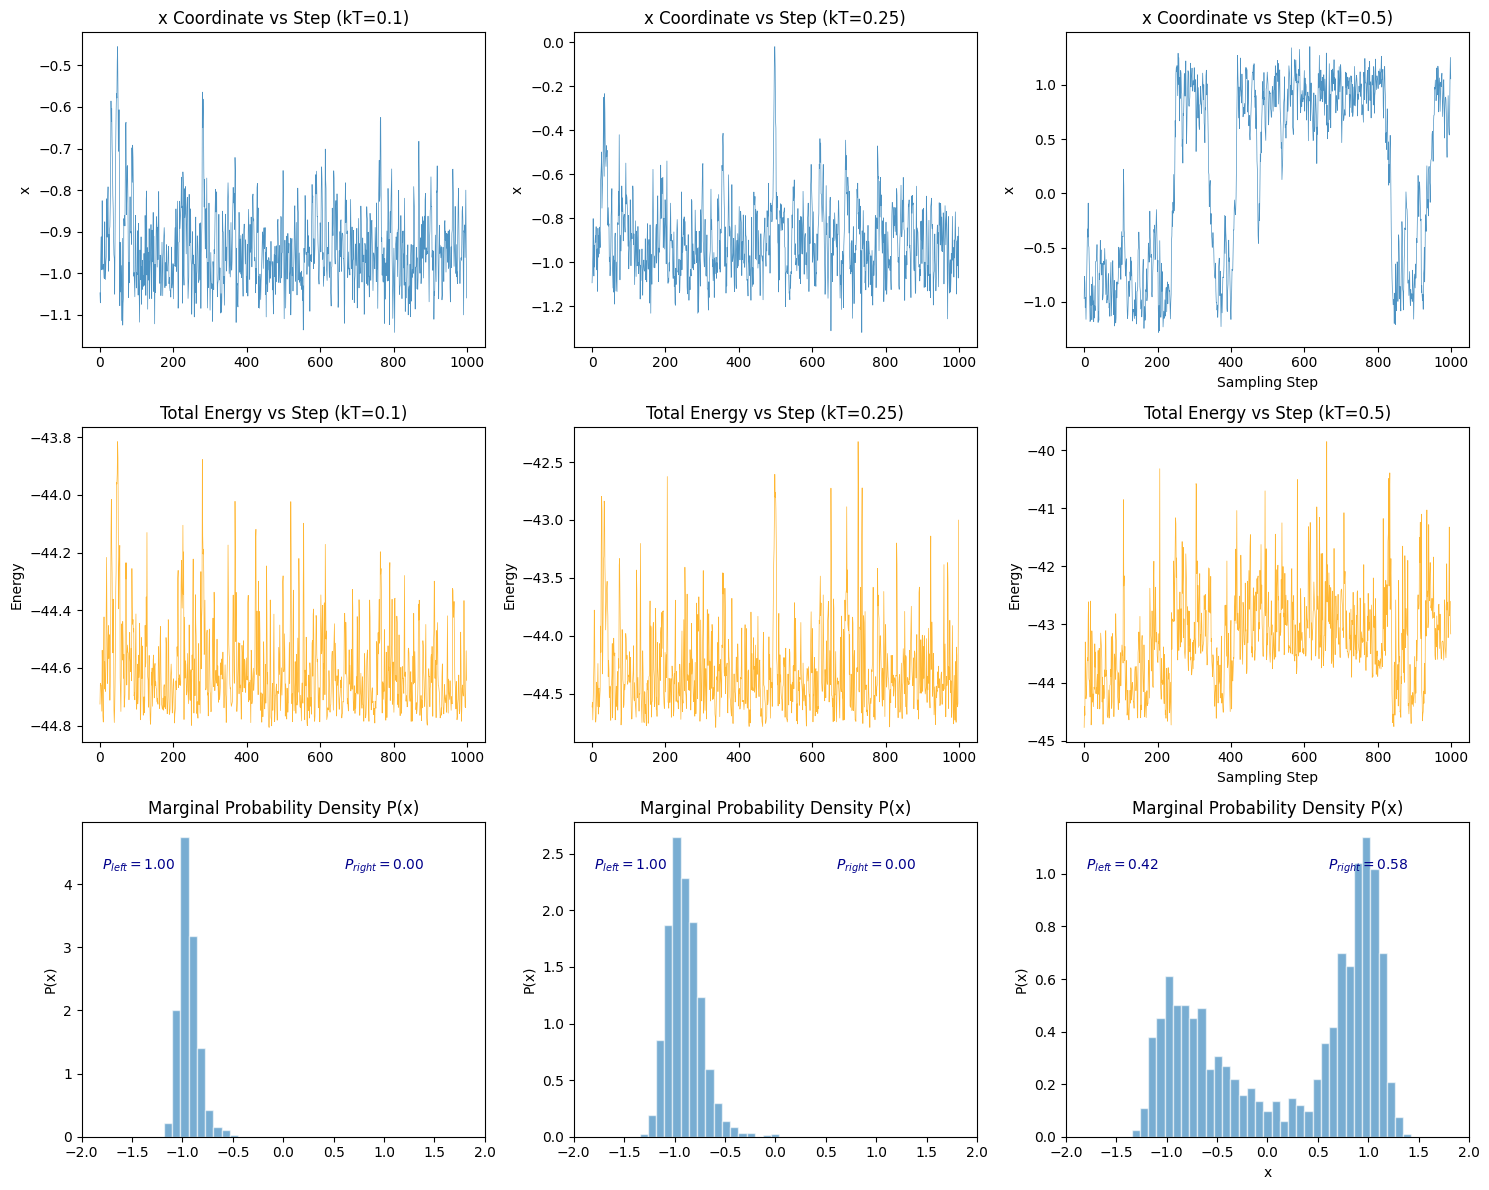

In [5]:
# Temperatures requested by the exercise
kT_values = [0.1, 0.25, 0.5]

# Simulation parameters
n_blocks = 1000       # Number of samples to take
steps_per_block = 30  # MD steps between each sample/thermostat application
dt = 0.01

# Setup a 3x3 grid of subplots (Rows: temperatures | Cols: x-trace, E-trace, P(x) histogram)
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

saved_x_samples = []

for i, kT in enumerate(kT_values):
    # Reset the final particle to its initial position and zero velocity
    cluster.pos[-1] = [-1.0, 0.0]
    cluster.set_velocity(np.zeros_like(cluster.pos))
    
    x_sampled = []
    e_sampled = []
    
    # Run the molecular dynamics simulation in blocks
    for block in range(n_blocks):
        # Apply Andersen thermostat to simulate a heat bath collision
        thermostat(cluster, kT)
        
        # Evolve deterministically for 'steps_per_block'
        pos, e = velocity_verlet(cluster, N=steps_per_block, dt=dt)
        
        # Sample the x-coordinate of the final particle and total energy
        x_sampled.append(pos[-1, 0])
        e_sampled.append(e)
    
    x_sampled = np.array(x_sampled)
    e_sampled = np.array(e_sampled)

    saved_x_samples.append(x_sampled)
    
    # Calculate populations by dividing the space at x = 0
    P_left = np.sum(x_sampled < 0) / len(x_sampled)
    P_right = np.sum(x_sampled >= 0) / len(x_sampled)
    
    # --- Plotting ---
    
    # 1. Normalized histogram approximating P(x)
    ax_hist = axes[2, i]
    ax_hist.hist(x_sampled, bins=np.linspace(-2, 2, 50), density=True, color='C0', alpha=0.6, edgecolor='white')
    ax_hist.set_title(f'Marginal Probability Density P(x)')
    ax_hist.set_ylabel('P(x)')
    if i == 2: ax_hist.set_xlabel('x')
    
    # Annotate P_left and P_right
    ax_hist.text(0.05, 0.85, f'$P_{{left}} = {P_left:.2f}$', transform=ax_hist.transAxes, color='darkblue')
    ax_hist.text(0.65, 0.85, f'$P_{{right}} = {P_right:.2f}$', transform=ax_hist.transAxes, color='darkblue')
    ax_hist.set_xlim(-2, 2)

    # 2. Sampled x coordinate vs sampling step
    ax_x = axes[0, i]
    ax_x.plot(x_sampled, lw=0.5, alpha=0.8)
    ax_x.set_title(f'x Coordinate vs Step (kT={kT})')
    ax_x.set_ylabel('x')
    if i == 2: ax_x.set_xlabel('Sampling Step')
    
    # 3. Sampled potential energy vs sampling step
    ax_e = axes[1, i]
    ax_e.plot(e_sampled, lw=0.5, alpha=0.8, color='orange')
    ax_e.set_title(f'Total Energy vs Step (kT={kT})')
    ax_e.set_ylabel('Energy')
    if i == 2: ax_e.set_xlabel('Sampling Step')
    
    
plt.tight_layout()
plt.show()

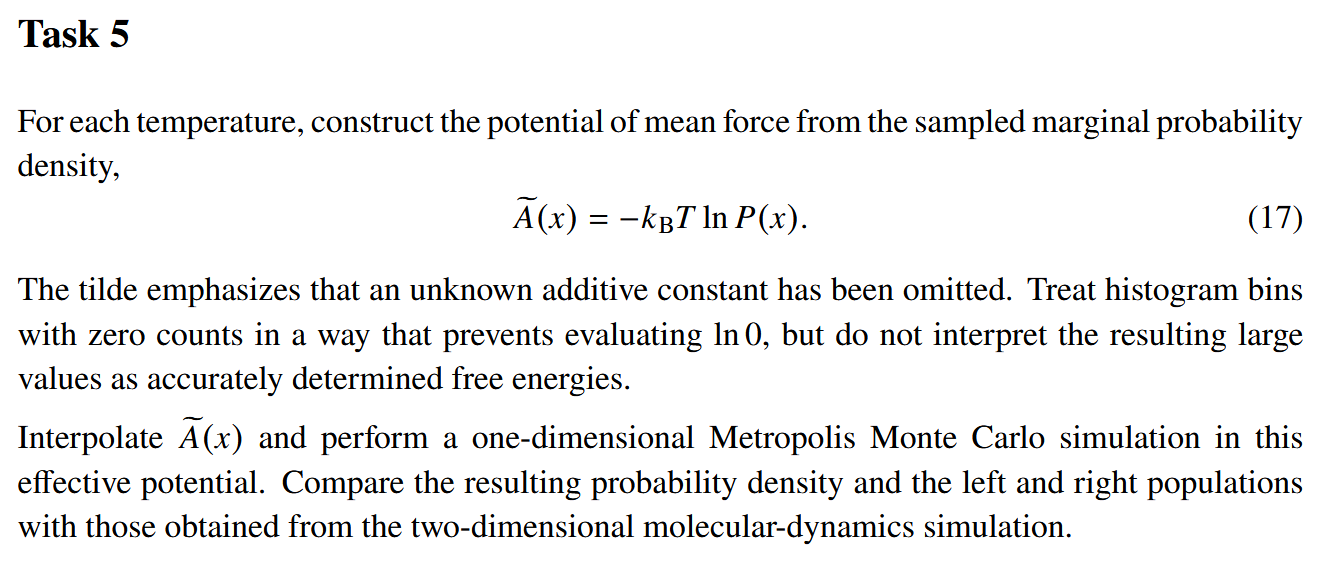
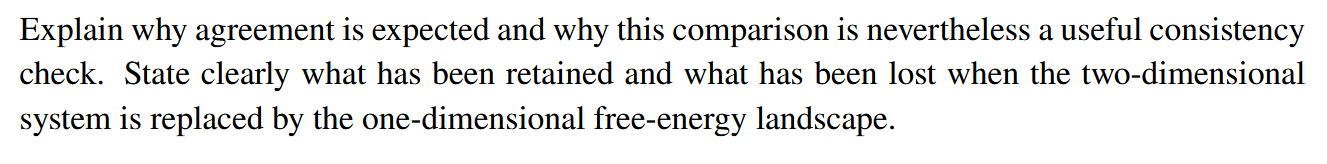
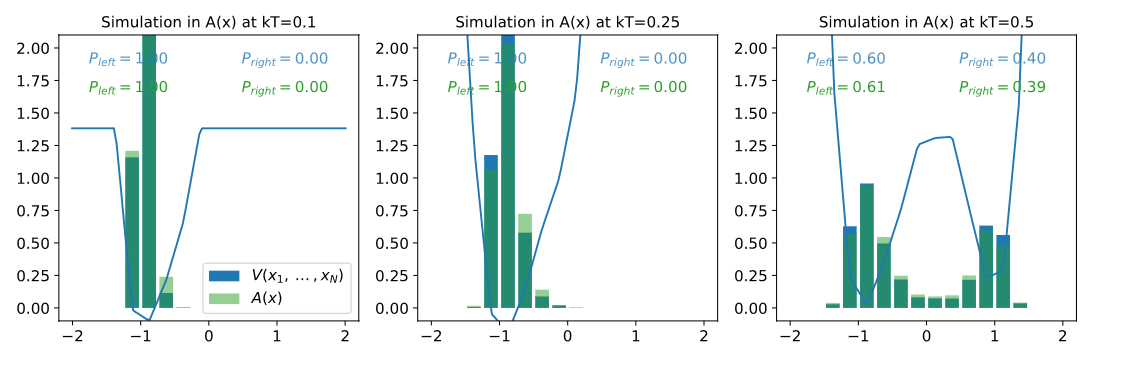

Sample size: 50000
Sample size: 50000
Sample size: 50000


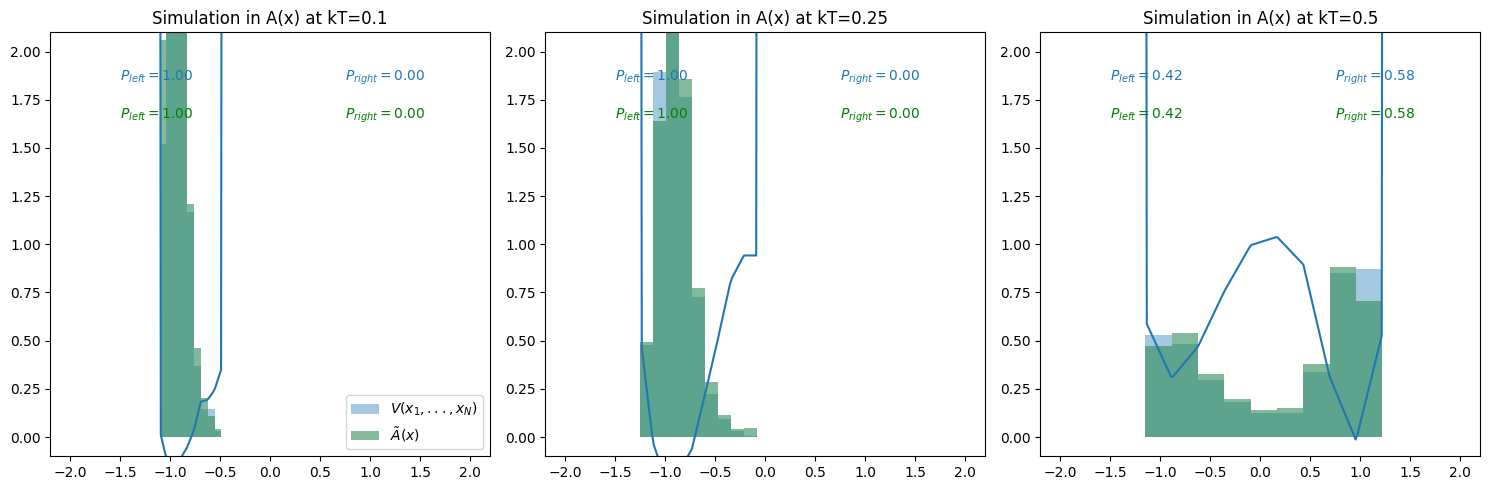

: 

In [ ]:
from scipy.interpolate import interp1d
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, kT in enumerate(kT_values):
    ax = axes[i]
    
    # 1. Retrieve the sampled x-coordinates from your MD simulation in Task 4
    x_md = saved_x_samples[i] 
    
    # 2. Construct P(x) from MD samples
    counts, bin_edges = np.histogram(x_md, bins=10, density=True)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    
    mask = counts > 0
    x_valid = bin_centers[mask]
    
    # 3. Calculate A_tilde(x)
    A_tilde = -kT * np.log(counts[mask])
    a_approx = interp1d(x_valid, A_tilde, bounds_error=False, fill_value=10.0)
    
    # 4. Perform 1D Metropolis Monte Carlo sampling
    mc_1d = MonteCarlo1D(a_approx, Nsim=50000, transition_method='uniform', kT=kT)
    x_mc = mc_1d.sample
    
    # --- CUSTOM PLOTTING TO MATCH TASK 5 DESCRIPTION ---
    
    # Plot MD histogram (Blue, V)
    ax.hist(x_md, bins=bin_centers, density=True, color='C0', alpha=0.4, label='$V(x_1, ..., x_N)$')
    
    # Plot MC histogram (Green, A_tilde)
    ax.hist(x_mc, bins=bin_centers, density=True, color='seagreen', alpha=0.6, label='$\\tilde{A}(x)$')
    
    # Plot the effective potential curve A_tilde(x)
    xs = np.linspace(-2, 2, 200)
    ax.plot(xs, a_approx(xs), color='C0', lw=1.5)
    
    # Calculate populations
    P_left_md = np.sum(x_md < 0) / len(x_md)
    P_right_md = np.sum(x_md >= 0) / len(x_md)
    P_left_mc = np.sum(x_mc < 0) / len(x_mc)
    P_right_mc = np.sum(x_mc >= 0) / len(x_mc)
    
    # Add text labels 
    ax.text(-1.5, 1.85, f'$P_{{left}} = {P_left_md:.2f}$', color='C0')
    ax.text(0.75, 1.85, f'$P_{{right}} = {P_right_md:.2f}$', color='C0')
    ax.text(-1.5, 1.65, f'$P_{{left}} = {P_left_mc:.2f}$', color='green')
    ax.text(0.75, 1.65, f'$P_{{right}} = {P_right_mc:.2f}$', color='green')
    
    # Lock the Y-axis so the potential isn't squished!
    ax.set_ylim(-0.1, 2.1)
    ax.set_xlim(-2.2, 2.2)
    ax.set_title(f'Simulation in A(x) at kT={kT}')
    
    if i == 0:
        ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

### Conceptual Explanations

**Why agreement is expected:**
The effective potential $\tilde{A}(x)$ is mathematically derived directly from the exact spatial distribution $P(x)$ of the MD simulation via the inverse Boltzmann relation. By feeding this exact free-energy profile back into a Monte Carlo sampler governed by the same temperature, thermodynamic consistency dictates that the sampler must reproduce the original input distribution.

**Why it is a useful consistency check:**
It independently verifies the integrity of your Metropolis Monte Carlo algorithm. If the 1D Monte Carlo algorithm fails to reproduce the known populations from the MD simulation, it exposes issues with the MC implementation—such as broken detailed balance, poorly tuned step sizes causing barrier-crossing failures, or insufficient sampling steps.

**What is retained:**
The exact thermodynamic equilibrium statistics along the $x$-coordinate are perfectly preserved. This includes the statistical weighting of all entropic effects and thermal fluctuations generated by the other particles and spatial dimensions, which are now implicitly baked into the shape of $\tilde{A}(x)$.

**What is lost:**
All dynamic and structural information is erased. You lose the time domain (kinematics, barrier-crossing rates, and collision frequencies), the explicit $y$-coordinates of the final particle, and the specific geometric correlations between the moving particle and the 14 frozen particles.